# Notebook 02 — Bulk RNA-seq preprocessing, normalization & sample-level QC
## GSE136666 — Substantia nigra discovery cohort

### Objective
Prepare the **10 substantia nigra libraries** from GSE136666 for differential-expression analysis in Notebook 03.

### Questions
1. Which low-count filtering rule is appropriate for the primary SN analysis?
2. Do DESeq2-style size factors reveal large sequencing-depth differences?
3. Do normalized samples cluster by disease, sex, or an unexpected technical pattern?
4. Are any libraries potential outliers?
5. Is the design `~ disease` or `~ sex + disease` statistically preferable for this small cohort?

### Scope
This notebook performs **preprocessing and QC only**. It does **not** declare DEGs. Raw integer counts remain unchanged for future inferential models.

In [1]:
# 0. Imports and reproducibility
from pathlib import Path
import csv, re, json, sys, platform, importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import gmean, spearmanr
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import patsy

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('PyDESeq2 installed:', importlib.util.find_spec('pydeseq2') is not None)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
pandas: 2.2.3
numpy: 2.3.5
PyDESeq2 installed: False


In [2]:
# 1. Project folders and flexible input discovery
PROJECT_ROOT = Path.cwd()
SEARCH_ROOTS = [PROJECT_ROOT, PROJECT_ROOT.parent, PROJECT_ROOT/'data', PROJECT_ROOT.parent/'data', Path('/mnt/data')]

RESULTS_DIR = PROJECT_ROOT/'results'/'bulk_preprocessing'
FIGURES_DIR = PROJECT_ROOT/'figures'/'bulk_preprocessing'
EXPORT_DIR = PROJECT_ROOT/'data'/'processed'/'notebook02'
for d in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]: d.mkdir(parents=True, exist_ok=True)

def find_file(patterns):
    if isinstance(patterns, str): patterns=[patterns]
    matches=[]
    for root in SEARCH_ROOTS:
        if not root.exists(): continue
        for pat in patterns: matches.extend(root.rglob(pat))
    matches=sorted(set(p.resolve() for p in matches if p.is_file()))
    return matches[0] if matches else None

COUNTS_FILE=find_file(['GSE136666_raw_counts_GRCh38.p13_NCBI*.tsv','*GSE136666*raw_counts*.tsv'])
CLEAN_META=find_file(['GSE136666_metadata_clean.csv'])
SERIES_META=find_file(['GSE136666_series_matrix*.txt','*GSE136666*series_matrix*.txt'])
FILTER_FLAGS=find_file(['GSE136666_candidate_filter_flags.csv'])

print('Counts:', COUNTS_FILE)
print('Clean metadata from Notebook 01:', CLEAN_META)
print('Series matrix fallback:', SERIES_META)
print('Filter flags from Notebook 01:', FILTER_FLAGS)
assert COUNTS_FILE is not None
assert CLEAN_META is not None or SERIES_META is not None

Counts: /mnt/data/GSE136666_raw_counts_GRCh38.p13_NCBI(1).tsv
Clean metadata from Notebook 01: None
Series matrix fallback: /mnt/data/GSE136666_series_matrix(1).txt
Filter flags from Notebook 01: None


In [3]:
# 2. GEO parser fallback, so Notebook 02 can run independently if Notebook 01 outputs are absent

def parse_geo_series_matrix(path):
    raw_fields={}; characteristic_rows=[]
    with open(path,'r',encoding='utf-8') as f:
        for line in f:
            line=line.rstrip('\n')
            if not line.startswith('!'): continue
            parts=next(csv.reader([line], delimiter='\t', quotechar='"'))
            key, values=parts[0], parts[1:]
            if key=='!Sample_characteristics_ch1': characteristic_rows.append(values)
            else: raw_fields.setdefault(key,[]).append(values)
    titles=raw_fields['!Sample_title'][0]; accessions=raw_fields['!Sample_geo_accession'][0]
    meta=pd.DataFrame({'sample_title':titles,'geo_accession':accessions})
    for values in characteristic_rows:
        if len(values)!=len(meta): continue
        prefixes=[]; parsed=[]
        for value in values:
            if ':' in value:
                k,v=value.split(':',1); prefixes.append(k.strip().lower()); parsed.append(v.strip())
            else:
                prefixes.append(None); parsed.append(value.strip())
        valid=[p for p in prefixes if p is not None]
        if valid and len(set(valid))==1:
            col=re.sub(r'[^a-z0-9]+','_',valid[0]).strip('_')
            meta[col]=parsed
    if 'gender' in meta:
        meta['sex']=meta['gender'].str.upper().replace({'F':'Female','M':'Male'})
    meta['disease']=meta['disease_state'].replace({'Control':'Control','Parkinson’s disease':'Parkinson',"Parkinson's disease":'Parkinson'})
    meta['tissue_clean']=meta['tissue'].replace({'Substantia nigra':'Substantia_nigra','Putamen':'Putamen'})
    return meta

if CLEAN_META is not None:
    meta=pd.read_csv(CLEAN_META)
else:
    meta=parse_geo_series_matrix(SERIES_META)

display(meta)

,sample_title,geo_accession,gender,disease_state,tissue,sex,disease,tissue_clean
0,SN_C_1,GSM4054763,f,Control,Substantia nigra,Female,Control,Substantia_nigra
1,SN_C_2,GSM4054764,f,Control,Substantia nigra,Female,Control,Substantia_nigra
2,SN_C_3,GSM4054765,m,Control,Substantia nigra,Male,Control,Substantia_nigra
3,SN_C_4,GSM4054766,m,Control,Substantia nigra,Male,Control,Substantia_nigra
4,SN_C_5,GSM4054767,m,Control,Substantia nigra,Male,Control,Substantia_nigra
5,SN_PD_1,GSM4054768,f,Parkinson’s disease,Substantia nigra,Female,Parkinson,Substantia_nigra
6,SN_PD_2,GSM4054769,f,Parkinson’s disease,Substantia nigra,Female,Parkinson,Substantia_nigra
7,SN_PD_3,GSM4054770,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra
8,SN_PD_4,GSM4054771,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra
9,SN_PD_5,GSM4054772,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra


## 3. Restrict the discovery analysis to substantia nigra

The primary comparison is **5 Parkinson vs 5 Control SN libraries**. Putamen is deliberately excluded from the primary model so tissue differences cannot dominate the Parkinson contrast.

In [4]:
# 3. Load counts and align metadata
raw=pd.read_csv(COUNTS_FILE, sep='\t')
assert 'GeneID' in raw.columns
counts_all=raw.set_index('GeneID')

sample_cols=list(counts_all.columns)
assert set(sample_cols)==set(meta['geo_accession']), 'Count columns and metadata do not match.'
meta=meta.set_index('geo_accession').loc[sample_cols].reset_index()

sn_meta=meta.loc[meta['tissue_clean']=='Substantia_nigra'].copy()
sn_ids=sn_meta['geo_accession'].tolist()
sn_counts=counts_all[sn_ids].copy()

print('SN count matrix:', sn_counts.shape)
print('Disease balance:')
display(sn_meta['disease'].value_counts())
print('Sex × disease:')
display(pd.crosstab(sn_meta['sex'], sn_meta['disease']))

assert sn_counts.shape[1]==10
assert set(sn_meta['disease'])=={'Control','Parkinson'}

SN count matrix: (39376, 10)
Disease balance:


disease
Control      5
Parkinson    5
Name: count, dtype: int64

Sex × disease:


disease,Control,Parkinson
sex,,
Female,2,2
Male,3,3


In [5]:
# 4. Raw SN QC summary before filtering
raw_qc=pd.DataFrame({
    'geo_accession':sn_ids,
    'sample_title':sn_meta['sample_title'].values,
    'disease':sn_meta['disease'].values,
    'sex':sn_meta['sex'].values,
    'library_size':sn_counts.sum(axis=0).values,
    'detected_gt0':(sn_counts>0).sum(axis=0).values,
    'detected_ge10':(sn_counts>=10).sum(axis=0).values,
    'zero_fraction':(sn_counts==0).mean(axis=0).values,
})
display(raw_qc)
display(raw_qc[['library_size','detected_gt0','detected_ge10','zero_fraction']].describe().T)

,geo_accession,sample_title,disease,sex,library_size,detected_gt0,detected_ge10,zero_fraction
0,GSM4054763,SN_C_1,Control,Female,35180013,30231,22002,0.232248
1,GSM4054764,SN_C_2,Control,Female,24892521,28580,20301,0.274177
2,GSM4054765,SN_C_3,Control,Male,26440540,29506,21188,0.250660
3,GSM4054766,SN_C_4,Control,Male,40476935,30651,22471,0.221582
4,GSM4054767,SN_C_5,Control,Male,20159733,28703,20317,0.271053
5,GSM4054768,SN_PD_1,Parkinson,Female,33658164,29889,21869,0.240934
6,GSM4054769,SN_PD_2,Parkinson,Female,22395839,27854,19743,0.292615
7,GSM4054770,SN_PD_3,Parkinson,Male,27974207,29529,21337,0.250076
8,GSM4054771,SN_PD_4,Parkinson,Male,34424341,30109,21870,0.235346
9,GSM4054772,SN_PD_5,Parkinson,Male,33788470,29992,21739,0.238318


,count,mean,std,min,25%,50%,75%,max
library_size,10.0,2.993908e+07,6.509694e+06,2.015973e+07,2.527953e+07,3.081619e+07,3.426537e+07,4.047694e+07
detected_gt0,10.0,2.950440e+04,8.701875e+02,2.785400e+04,2.890375e+04,2.970900e+04,3.007975e+04,3.065100e+04
detected_ge10,10.0,2.128370e+04,8.885207e+02,1.974300e+04,2.053475e+04,2.153800e+04,2.186975e+04,2.247100e+04
zero_fraction,10.0,2.507009e-01,2.209944e-02,2.215817e-01,2.360892e-01,2.455049e-01,2.659552e-01,2.926148e-01


## 5. Low-count filtering decision

For the **primary SN-only analysis**, the default rule used here is:

> retain genes with **count ≥ 10 in at least 3 of the 10 SN libraries**.

Why this rule?
- it is defined on the tissue actually being modeled;
- it removes genes with extremely sparse information;
- requiring 3 libraries is less restrictive than demanding expression in an entire disease group;
- the threshold is fixed before differential testing.

Notebook 03 can include a sensitivity analysis using a less/more stringent alternative.

In [6]:
# 5. Compare candidate filters and choose the SN-specific rule
candidate_filters=pd.DataFrame({
    'criterion':['Total count >=10 in SN','Count >=10 in >=2 SN libraries','Count >=10 in >=3 SN libraries','Count >=10 in >=5 SN libraries'],
    'genes_retained':[
        int((sn_counts.sum(axis=1)>=10).sum()),
        int(((sn_counts>=10).sum(axis=1)>=2).sum()),
        int(((sn_counts>=10).sum(axis=1)>=3).sum()),
        int(((sn_counts>=10).sum(axis=1)>=5).sum()),
    ]
})
candidate_filters['fraction_retained']=candidate_filters['genes_retained']/sn_counts.shape[0]
display(candidate_filters)

KEEP_MASK=(sn_counts>=10).sum(axis=1)>=3
sn_counts_filt=sn_counts.loc[KEEP_MASK].copy()
print(f'Retained {sn_counts_filt.shape[0]:,} / {sn_counts.shape[0]:,} genes ({sn_counts_filt.shape[0]/sn_counts.shape[0]:.1%}).')
assert sn_counts_filt.shape[0]>1000

,criterion,genes_retained,fraction_retained
0,Total count >=10 in SN,28662,0.727905
1,Count >=10 in >=2 SN libraries,22976,0.583503
2,Count >=10 in >=3 SN libraries,22369,0.568087
3,Count >=10 in >=5 SN libraries,21512,0.546323


Retained 22,369 / 39,376 genes (56.8%).


In [7]:
# 6. DESeq2-style median-of-ratios size-factor normalization
# This function implements the standard median-ratio idea for QC/preprocessing.
# Genes with a zero in any sample are excluded from the geometric-mean reference.

def deseq2_median_ratio_size_factors(counts_genes_by_samples):
    X=counts_genes_by_samples.astype(float)
    positive_all=(X>0).all(axis=1)
    ref=X.loc[positive_all]
    if ref.empty:
        raise ValueError('No genes are positive in every sample; cannot compute classic geometric means.')
    geom_means=np.exp(np.log(ref).mean(axis=1))
    ratios=ref.div(geom_means, axis=0)
    sf=ratios.median(axis=0)
    # Normalize around geometric mean 1 for interpretability.
    sf=sf/np.exp(np.log(sf).mean())
    return sf, positive_all

size_factors, sf_reference_mask=deseq2_median_ratio_size_factors(sn_counts_filt)
normalized_counts=sn_counts_filt.div(size_factors, axis=1)

sf_table=pd.DataFrame({
    'geo_accession':sn_ids,
    'sample_title':sn_meta['sample_title'].values,
    'disease':sn_meta['disease'].values,
    'sex':sn_meta['sex'].values,
    'raw_library_size':sn_counts_filt.sum(axis=0).values,
    'size_factor':size_factors.loc[sn_ids].values,
    'normalized_library_sum':normalized_counts.sum(axis=0).values,
})
display(sf_table)
print('Genes used to estimate classic geometric-mean reference:', int(sf_reference_mask.sum()))

,geo_accession,sample_title,disease,sex,raw_library_size,size_factor,normalized_library_sum
0,GSM4054763,SN_C_1,Control,Female,35150682,1.283736,2.738154e+07
1,GSM4054764,SN_C_2,Control,Female,24876992,0.780721,3.186413e+07
2,GSM4054765,SN_C_3,Control,Male,26420014,0.901020,2.932234e+07
3,GSM4054766,SN_C_4,Control,Male,40445617,1.468564,2.754094e+07
4,GSM4054767,SN_C_5,Control,Male,20144014,0.688912,2.924034e+07
5,GSM4054768,SN_PD_1,Parkinson,Female,33633254,1.281770,2.623969e+07
6,GSM4054769,SN_PD_2,Parkinson,Female,22381486,0.635539,3.521652e+07
7,GSM4054770,SN_PD_3,Parkinson,Male,27952970,1.000881,2.792837e+07
8,GSM4054771,SN_PD_4,Parkinson,Male,34398880,1.209947,2.843007e+07
9,GSM4054772,SN_PD_5,Parkinson,Male,33762748,1.109523,3.042997e+07


Genes used to estimate classic geometric-mean reference: 22154


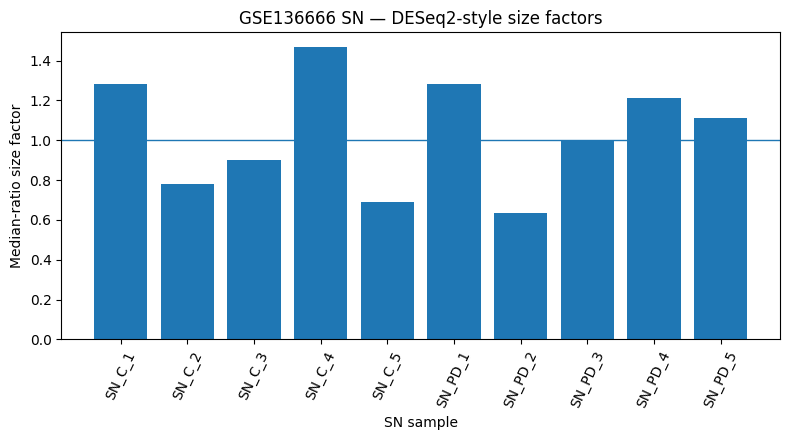

In [8]:
# 7. Size-factor diagnostics
fig, ax=plt.subplots(figsize=(8,4.5))
ax.bar(sf_table['sample_title'], sf_table['size_factor'])
ax.axhline(1.0, linewidth=1)
ax.set_ylabel('Median-ratio size factor')
ax.set_xlabel('SN sample')
ax.set_title('GSE136666 SN — DESeq2-style size factors')
ax.tick_params(axis='x', rotation=65)
fig.tight_layout()
fig.savefig(FIGURES_DIR/'SN_size_factors.png', dpi=300, bbox_inches='tight')
plt.show()

Spearman rho = 0.952, p = 2.28e-05


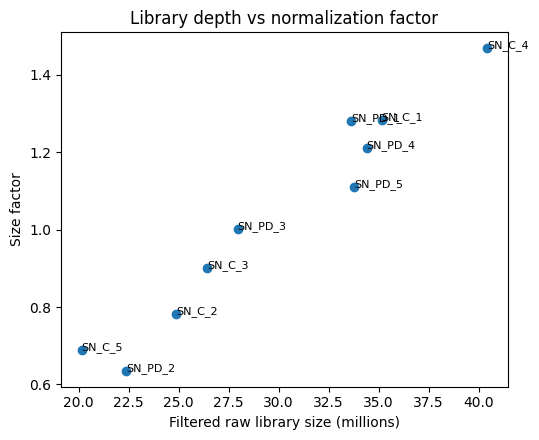

In [9]:
# 8. Raw library size vs size factor
rho, p=spearmanr(sf_table['raw_library_size'], sf_table['size_factor'])
print(f'Spearman rho = {rho:.3f}, p = {p:.4g}')

fig, ax=plt.subplots(figsize=(5.5,4.5))
ax.scatter(sf_table['raw_library_size']/1e6, sf_table['size_factor'])
for _,r in sf_table.iterrows():
    ax.annotate(r['sample_title'], (r['raw_library_size']/1e6,r['size_factor']), fontsize=8)
ax.set_xlabel('Filtered raw library size (millions)')
ax.set_ylabel('Size factor')
ax.set_title('Library depth vs normalization factor')
fig.tight_layout()
fig.savefig(FIGURES_DIR/'SN_library_size_vs_size_factor.png',dpi=300,bbox_inches='tight')
plt.show()

## 9. Transformation for PCA and sample-level QC

For unsupervised visualization we use `log2(normalized_count + 1)` in this notebook. This is **not** the count matrix used for differential-expression inference. Notebook 03 will use raw integer counts with a negative-binomial model.

A true DESeq2 VST can be added through PyDESeq2 when available, but PCA conclusions should be checked for robustness rather than depend on one transformation.

In [10]:
# 9. Log-normalized matrix for exploratory PCA/QC
log_norm=np.log2(normalized_counts+1)

# Most variable genes improve sample-level PCA readability without using disease labels.
gene_var=log_norm.var(axis=1)
N_TOP=min(3000, len(gene_var))
top_var_genes=gene_var.nlargest(N_TOP).index
pca_input=log_norm.loc[top_var_genes].T

# Center each gene; no variance scaling is needed because genes were selected by variance.
X=pca_input - pca_input.mean(axis=0)
pca=PCA(n_components=min(5, X.shape[0]-1), random_state=RANDOM_STATE)
pc_scores=pca.fit_transform(X)

pca_df=pd.DataFrame(pc_scores, index=pca_input.index, columns=[f'PC{i+1}' for i in range(pc_scores.shape[1])]).reset_index(names='geo_accession')
pca_df=pca_df.merge(sn_meta[['geo_accession','sample_title','disease','sex']], on='geo_accession', how='left')

print('Explained variance ratio:')
for i,v in enumerate(pca.explained_variance_ratio_,1): print(f'PC{i}: {v:.2%}')
display(pca_df)

Explained variance ratio:
PC1: 31.75%
PC2: 18.16%
PC3: 11.78%
PC4: 9.34%
PC5: 8.47%


,geo_accession,PC1,PC2,PC3,PC4,PC5,sample_title,disease,sex
0,GSM4054763,-4.867827,39.257376,35.731188,1.474420,-0.797752,SN_C_1,Control,Female
1,GSM4054764,-11.460399,30.103117,-25.367655,27.522177,12.320724,SN_C_2,Control,Female
2,GSM4054765,16.620868,-21.649598,-7.644738,2.523729,23.109679,SN_C_3,Control,Male
3,GSM4054766,14.035240,-6.677556,14.642371,15.077005,1.982943,SN_C_4,Control,Male
4,GSM4054767,46.709507,-3.829399,-0.321981,-15.972962,15.882357,SN_C_5,Control,Male
5,GSM4054768,2.798285,23.400322,-26.874976,-27.716615,-12.786311,SN_PD_1,Parkinson,Female
6,GSM4054769,-72.719571,-10.961620,4.752107,-15.313271,10.946911,SN_PD_2,Parkinson,Female
7,GSM4054770,13.093281,-14.980217,15.044539,-8.359423,-7.152562,SN_PD_3,Parkinson,Male
8,GSM4054771,11.645589,-1.727938,-4.157518,7.919472,-28.391249,SN_PD_4,Parkinson,Male
9,GSM4054772,-15.854972,-32.934487,-5.803337,12.845468,-15.114740,SN_PD_5,Parkinson,Male


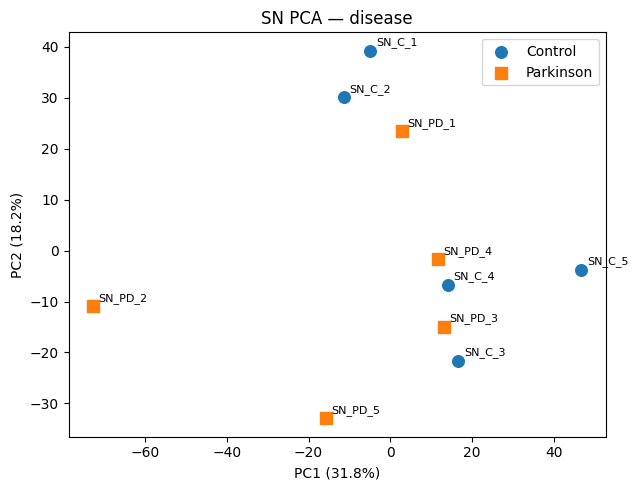

In [11]:
# 10. PCA plot — disease labels
fig, ax=plt.subplots(figsize=(6.5,5))
markers={'Control':'o','Parkinson':'s'}
for group,sub in pca_df.groupby('disease'):
    ax.scatter(sub['PC1'],sub['PC2'],label=group,marker=markers.get(group,'o'),s=70)
    for _,r in sub.iterrows(): ax.annotate(r['sample_title'],(r['PC1'],r['PC2']),fontsize=8,xytext=(4,4),textcoords='offset points')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title('SN PCA — disease')
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR/'SN_PCA_disease.png',dpi=300,bbox_inches='tight'); plt.show()

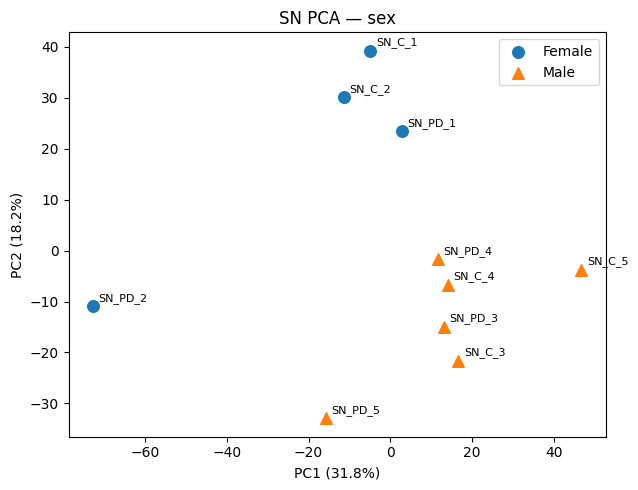

In [12]:
# 11. PCA plot — sex labels
fig, ax=plt.subplots(figsize=(6.5,5))
markers={'Female':'o','Male':'^'}
for group,sub in pca_df.groupby('sex'):
    ax.scatter(sub['PC1'],sub['PC2'],label=group,marker=markers.get(group,'o'),s=70)
    for _,r in sub.iterrows(): ax.annotate(r['sample_title'],(r['PC1'],r['PC2']),fontsize=8,xytext=(4,4),textcoords='offset points')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title('SN PCA — sex')
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR/'SN_PCA_sex.png',dpi=300,bbox_inches='tight'); plt.show()

sample_title,SN_C_1,SN_C_2,SN_C_3,SN_C_4,SN_C_5,SN_PD_1,SN_PD_2,SN_PD_3,SN_PD_4,SN_PD_5
sample_title,,,,,,,,,,
SN_C_1,0.00,73.37,84.08,71.32,85.98,75.57,95.82,75.15,72.67,87.70
SN_C_2,73.37,0.00,76.17,72.85,88.30,67.43,92.20,80.74,70.56,78.69
SN_C_3,84.08,76.17,0.00,61.44,63.25,74.57,99.64,59.47,64.73,64.36
SN_C_4,71.32,72.85,61.44,0.00,65.19,74.17,98.10,57.62,58.53,65.46
SN_C_5,85.98,88.30,63.25,65.19,0.00,75.70,121.54,68.28,68.43,86.15
SN_PD_1,75.57,67.43,74.57,74.17,75.70,0.00,96.14,71.72,64.44,79.21
SN_PD_2,95.82,92.20,99.64,98.10,121.54,96.14,0.00,97.15,98.49,79.54
SN_PD_3,75.15,80.74,59.47,57.62,68.28,71.72,97.15,0.00,60.29,65.61
SN_PD_4,72.67,70.56,64.73,58.53,68.43,64.44,98.49,60.29,0.00,61.16


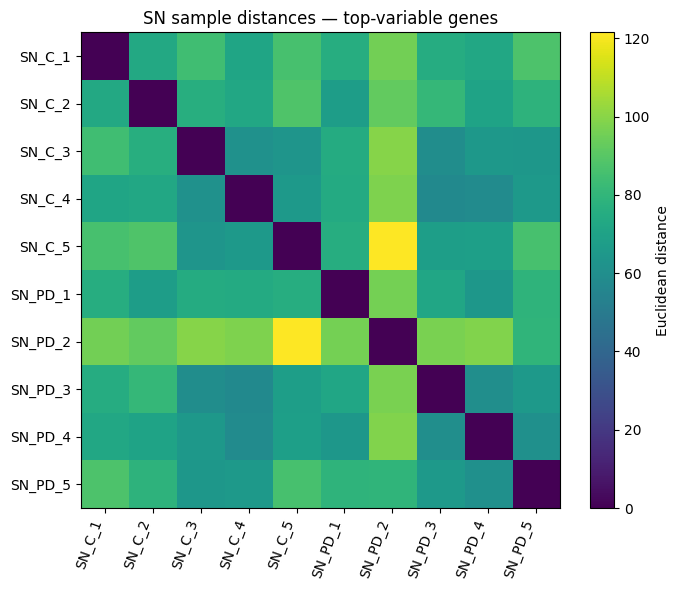

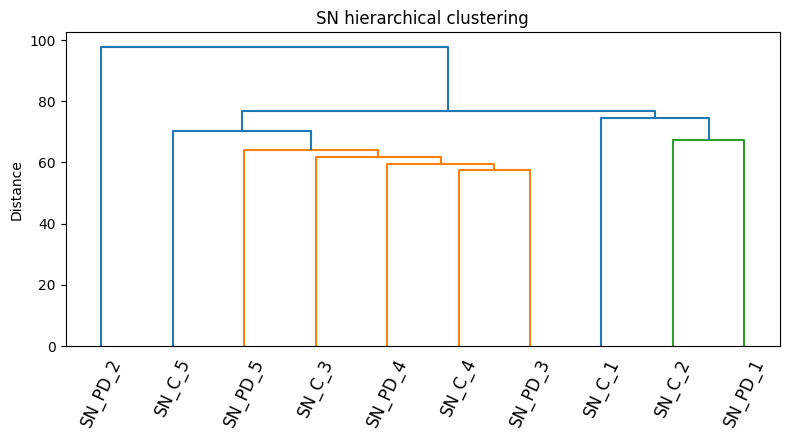

In [13]:
# 12. Sample-to-sample distance matrix and hierarchical clustering
sample_dist=squareform(pdist(pca_input, metric='euclidean'))
dist_df=pd.DataFrame(sample_dist,index=sn_meta['sample_title'],columns=sn_meta['sample_title'])
display(dist_df.round(2))

fig, ax=plt.subplots(figsize=(7,6))
im=ax.imshow(dist_df.values, aspect='auto')
ax.set_xticks(range(len(dist_df))); ax.set_xticklabels(dist_df.columns,rotation=70,ha='right')
ax.set_yticks(range(len(dist_df))); ax.set_yticklabels(dist_df.index)
ax.set_title('SN sample distances — top-variable genes')
fig.colorbar(im,ax=ax,label='Euclidean distance')
fig.tight_layout(); fig.savefig(FIGURES_DIR/'SN_sample_distance_heatmap.png',dpi=300,bbox_inches='tight'); plt.show()

Z=linkage(pca_input,method='average',metric='euclidean')
fig, ax=plt.subplots(figsize=(8,4.5))
dendrogram(Z, labels=sn_meta['sample_title'].tolist(), leaf_rotation=65, ax=ax)
ax.set_ylabel('Distance'); ax.set_title('SN hierarchical clustering')
fig.tight_layout(); fig.savefig(FIGURES_DIR/'SN_hierarchical_clustering.png',dpi=300,bbox_inches='tight'); plt.show()

## 13. Potential outlier screen

Because `n=10` is small, we do **not** automatically delete a sample because it looks unusual on PCA. We flag samples only for review using multiple sample-level metrics. Any exclusion in Notebook 03 must have a biological/technical rationale documented before viewing differential-expression significance.

In [14]:
# 13. Robust outlier flags for library depth and PCA distance

def robust_z(x):
    x=np.asarray(x,dtype=float); med=np.median(x); mad=np.median(np.abs(x-med))
    if mad==0: return np.zeros_like(x)
    return 0.67448975*(x-med)/mad

centroid=pca_df[['PC1','PC2']].mean(axis=0).to_numpy()
pca_radius=np.linalg.norm(pca_df[['PC1','PC2']].to_numpy()-centroid,axis=1)

outlier_qc=sf_table[['geo_accession','sample_title','disease','sex','raw_library_size','size_factor']].copy()
outlier_qc['library_robust_z']=robust_z(outlier_qc['raw_library_size'])
outlier_qc['size_factor_robust_z']=robust_z(outlier_qc['size_factor'])
outlier_qc['pca_radius']=pca_radius
outlier_qc['pca_radius_robust_z']=robust_z(pca_radius)
outlier_qc['review_flag']=(outlier_qc[['library_robust_z','size_factor_robust_z','pca_radius_robust_z']].abs()>3.5).any(axis=1)
display(outlier_qc)
print('Samples flagged for review:', outlier_qc.loc[outlier_qc['review_flag'],'sample_title'].tolist())

,geo_accession,sample_title,disease,sex,raw_library_size,size_factor,library_robust_z,size_factor_robust_z,pca_radius,pca_radius_robust_z,review_flag
0,GSM4054763,SN_C_1,Control,Female,35150682,1.283736,0.673290,0.677404,39.558025,0.672741,False
1,GSM4054764,SN_C_2,Control,Female,24876992,0.780721,-0.914102,-0.813594,32.210843,0.168669,False
2,GSM4054765,SN_C_3,Control,Male,26420014,0.901020,-0.675689,-0.457013,27.293925,-0.168669,False
3,GSM4054766,SN_C_4,Control,Male,40445617,1.468564,1.491413,1.225253,15.542770,-0.974886,False
4,GSM4054767,SN_C_5,Control,Male,20144014,0.688912,-1.645397,-1.085727,46.866217,1.174137,False
5,GSM4054768,SN_PD_1,Parkinson,Female,33633254,1.281770,0.438832,0.671576,23.567042,-0.424361,False
6,GSM4054769,SN_PD_2,Parkinson,Female,22381486,0.635539,-1.299684,-1.243929,73.541098,3.004234,False
7,GSM4054770,SN_PD_3,Parkinson,Male,27952970,1.000881,-0.438832,-0.161014,19.895751,-0.676239,False
8,GSM4054771,SN_PD_4,Parkinson,Male,34398880,1.209947,0.557129,0.458683,11.773084,-1.233515,False
9,GSM4054772,SN_PD_5,Parkinson,Male,33762748,1.109523,0.458840,0.161014,36.552162,0.466516,False


Samples flagged for review: []


## 14. Compare candidate model designs before Notebook 03

Sex is exactly balanced across disease in this SN subset, so it is **not a confounder of disease** here. With only 10 libraries, adding sex uses an additional degree of freedom. We therefore assess both model matrices now and reserve the final inferential choice for Notebook 03.

In [15]:
# 14. Design-matrix diagnostics
model_meta=sn_meta[['geo_accession','disease','sex']].copy()
model_meta['disease']=pd.Categorical(model_meta['disease'],categories=['Control','Parkinson'])
model_meta['sex']=pd.Categorical(model_meta['sex'],categories=['Female','Male'])

design_A=patsy.dmatrix('~ disease',model_meta,return_type='dataframe')
design_B=patsy.dmatrix('~ sex + disease',model_meta,return_type='dataframe')

def design_diagnostics(X,name):
    arr=np.asarray(X,dtype=float)
    return {
        'design':name,
        'n_samples':arr.shape[0],
        'n_parameters':arr.shape[1],
        'residual_df':arr.shape[0]-np.linalg.matrix_rank(arr),
        'matrix_rank':np.linalg.matrix_rank(arr),
        'full_rank':np.linalg.matrix_rank(arr)==arr.shape[1],
        'condition_number':np.linalg.cond(arr),
    }

design_summary=pd.DataFrame([design_diagnostics(design_A,'~ disease'),design_diagnostics(design_B,'~ sex + disease')])
display(design_summary)
print('\nDesign A columns:',design_A.columns.tolist())
print('Design B columns:',design_B.columns.tolist())

,design,n_samples,n_parameters,residual_df,matrix_rank,full_rank,condition_number
0,~ disease,10,2,8,2,True,2.618034
1,~ sex + disease,10,3,7,3,True,3.465640



Design A columns: ['Intercept', 'disease[T.Parkinson]']
Design B columns: ['Intercept', 'sex[T.Male]', 'disease[T.Parkinson]']


In [16]:
# 15. Exploratory association of PCs with disease and sex
# Effect-size-oriented QC only; NOT differential-expression testing.
pc_assoc=[]
for pc in ['PC1','PC2','PC3']:
    if pc not in pca_df: continue
    for var in ['disease','sex']:
        groups=[g[pc].to_numpy() for _,g in pca_df.groupby(var)]
        if len(groups)==2:
            means=[float(np.mean(x)) for x in groups]
            pooled=np.sqrt(np.mean([np.var(x,ddof=1) for x in groups if len(x)>1]))
            standardized_diff=(means[1]-means[0])/pooled if pooled>0 else np.nan
            pc_assoc.append({'PC':pc,'variable':var,'group_means':means,'standardized_mean_difference':standardized_diff})
pc_assoc=pd.DataFrame(pc_assoc)
display(pc_assoc)

,PC,variable,group_means,standardized_mean_difference
0,PC1,disease,"[12.207477704714103, -12.207477704714105]",-0.815292
1,PC1,sex,"[-21.562377858066295, 14.374918572044196]",1.273839
2,PC2,disease,"[7.440788113545582, -7.44078811354557]",-0.634448
3,PC2,sex,"[20.449798904931775, -13.633199269954508]",-1.926894
4,PC3,disease,"[3.4078370383844403, -3.4078370383844487]",-0.346282
5,PC3,sex,"[-2.9398339463528553, 1.9598892975685631]",0.221090


## 16. Optional PyDESeq2 compatibility check

This cell does not install packages automatically. If `pydeseq2` is available, it builds a `DeseqDataSet` object using the filtered raw SN counts. If it is not installed, the rest of Notebook 02 remains fully executable because the QC normalization above is implemented directly in Python.

In [17]:
# 16. Optional PyDESeq2 object preparation
HAS_PYDESEQ2=importlib.util.find_spec('pydeseq2') is not None

if HAS_PYDESEQ2:
    from pydeseq2.dds import DeseqDataSet
    counts_for_pydeseq2=sn_counts_filt.T.astype(int)
    metadata_for_pydeseq2=sn_meta.set_index('geo_accession').loc[counts_for_pydeseq2.index,["disease","sex"]].copy()
    dds=DeseqDataSet(counts=counts_for_pydeseq2, metadata=metadata_for_pydeseq2, design='~ disease')
    print('PyDESeq2 object created successfully:',dds)
else:
    print('PyDESeq2 is not installed in this environment.')
    print('For Notebook 03, install it in your local environment if you want the PyDESeq2 inference route.')

PyDESeq2 is not installed in this environment.
For Notebook 03, install it in your local environment if you want the PyDESeq2 inference route.


In [18]:
# 17. Export Notebook 02 outputs
sn_meta.to_csv(EXPORT_DIR/'GSE136666_SN_metadata.csv',index=False)
sn_counts_filt.to_csv(EXPORT_DIR/'GSE136666_SN_filtered_raw_counts.csv')
normalized_counts.to_csv(EXPORT_DIR/'GSE136666_SN_median_ratio_normalized_counts.csv')
log_norm.to_csv(EXPORT_DIR/'GSE136666_SN_log2_normalized_counts.csv')
sf_table.to_csv(RESULTS_DIR/'GSE136666_SN_size_factors.csv',index=False)
candidate_filters.to_csv(RESULTS_DIR/'GSE136666_SN_filter_comparison.csv',index=False)
pca_df.to_csv(RESULTS_DIR/'GSE136666_SN_PCA_scores.csv',index=False)
dist_df.to_csv(RESULTS_DIR/'GSE136666_SN_sample_distances.csv')
outlier_qc.to_csv(RESULTS_DIR/'GSE136666_SN_outlier_screen.csv',index=False)
design_summary.to_csv(RESULTS_DIR/'GSE136666_SN_design_comparison.csv',index=False)
pc_assoc.to_csv(RESULTS_DIR/'GSE136666_SN_PC_associations.csv',index=False)

manifest={
    'dataset':'GSE136666',
    'tissue':'Substantia nigra',
    'n_samples':int(sn_counts_filt.shape[1]),
    'n_genes_before_filter':int(sn_counts.shape[0]),
    'n_genes_after_filter':int(sn_counts_filt.shape[0]),
    'filter_rule':'count >= 10 in at least 3 SN libraries',
    'normalization':'DESeq2-style median of ratios for QC',
    'transformation_for_qc':'log2(normalized_count + 1)',
    'primary_candidate_design':'~ disease',
    'sensitivity_candidate_design':'~ sex + disease',
    'next_notebook':'03_bulk_differential_expression.ipynb'
}
with open(EXPORT_DIR/'notebook02_manifest.json','w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)

print('Exports created in:',EXPORT_DIR.resolve())
print('Results created in:',RESULTS_DIR.resolve())
print('Figures created in:',FIGURES_DIR.resolve())

Exports created in: /mnt/data/data/processed/notebook02
Results created in: /mnt/data/results/bulk_preprocessing
Figures created in: /mnt/data/figures/bulk_preprocessing


In [19]:
# 18. Final automated checkpoint
checks={
    '10 SN libraries retained':sn_counts_filt.shape[1]==10,
    '5 Control + 5 Parkinson':sn_meta['disease'].value_counts().to_dict()=={'Control':5,'Parkinson':5},
    'No negative counts':bool((sn_counts_filt>=0).all().all()),
    'All filtered raw counts integer-valued':bool(np.allclose(sn_counts_filt.to_numpy(),np.round(sn_counts_filt.to_numpy()))),
    'All size factors finite':bool(np.isfinite(size_factors).all()),
    'All size factors positive':bool((size_factors>0).all()),
    'Design ~ disease full rank':bool(design_summary.loc[design_summary['design']=='~ disease','full_rank'].iloc[0]),
    'Design ~ sex + disease full rank':bool(design_summary.loc[design_summary['design']=='~ sex + disease','full_rank'].iloc[0]),
}
checkpoint=pd.Series(checks,name='passed')
display(checkpoint)
assert checkpoint.all(), 'Notebook 02 checkpoint failed; inspect the relevant QC section.'
print('\n✓ Notebook 02 passed. Data are prepared for differential-expression modeling in Notebook 03.')

10 SN libraries retained                  True
5 Control + 5 Parkinson                   True
No negative counts                        True
All filtered raw counts integer-valued    True
All size factors finite                   True
All size factors positive                 True
Design ~ disease full rank                True
Design ~ sex + disease full rank          True
Name: passed, dtype: bool


✓ Notebook 02 passed. Data are prepared for differential-expression modeling in Notebook 03.


# Interpretation and decision log

Before starting Notebook 03, record the following from the executed outputs:

1. **Filtering:** how many genes remain after the prespecified SN filter?
2. **Normalization:** are any size factors extreme?
3. **PCA:** does disease, sex, or neither dominate the first PCs?
4. **Outliers:** did any sample trigger the multimetric review flag?
5. **Model design:** both designs should be full rank. Because sex is balanced by disease, `~ disease` is a defensible primary model; `~ sex + disease` can be used as a sensitivity model. If QC reveals a strong sex-associated axis, report both and compare robustness.

## Inputs for Notebook 03
- `GSE136666_SN_filtered_raw_counts.csv`
- `GSE136666_SN_metadata.csv`
- `GSE136666_SN_size_factors.csv`
- PCA/outlier/design-QC results

Notebook 03 will perform the **negative-binomial differential-expression analysis**, multiple-testing correction, effect-size estimation/shrinkage strategy, MA/volcano plots, and sensitivity comparison of the two model designs.